In [4]:
import pandas as pd
from tqdm.auto import tqdm
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

tqdm.pandas()

# Load the data

In [5]:
spotify_tracks = pd.read_csv('spotify_tracks_pop.csv')
display(pd.read_csv('spotify_tracks_pop.csv').head(5))
spotify_tracks['track_album_release_date'] = pd.to_datetime(spotify_tracks['track_album_release_date'])
spotify_tracks.shape

,id,energy,tempo,danceability,loudness,liveness,valence,time_signature,speechiness,track_album_release_date,...,key,duration_min,acousticness,first_listed_artist,track_album_name,playlist_name,playlist_genre,playlist_subgenre,track_name,track_popularity
0,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Today's Top Hits,pop,mainstream,Die With A Smile,100
1,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Global Top 50,pop,global,Die With A Smile,100
2,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Top Gaming Tracks,gaming,modern,Die With A Smile,100
3,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,0.0,2.831950,0.0283,ROSÉ,APT.,Today's Top Hits,pop,mainstream,APT.,98
4,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,0.0,2.831950,0.0283,ROSÉ,APT.,Global Top 50,pop,global,APT.,98


(4684, 22)

In [8]:
spotify_tracks.dtypes

id                                     str
energy                             float64
tempo                              float64
danceability                       float64
loudness                           float64
liveness                           float64
valence                            float64
time_signature                         str
speechiness                        float64
track_album_release_date    datetime64[us]
instrumentalness                   float64
mode                                   str
key                                float64
duration_min                       float64
acousticness                       float64
first_listed_artist                    str
track_album_name                       str
playlist_name                          str
playlist_genre                         str
playlist_subgenre                      str
track_name                             str
track_popularity                     int64
dtype: object

# First we're going to look at how we could potentially bin the song popularity scale into at least three levels. The thinking is that it would be good to have at least, low, medium, and high popularity buckets for songs.

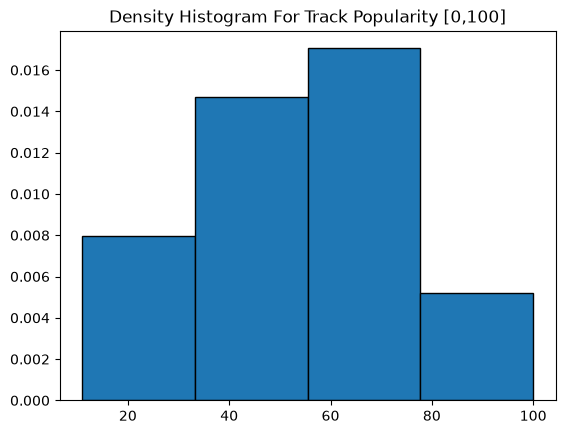

[ 11.    33.25  55.5   77.75 100.  ]


In [51]:
_, bins, _ = plt.hist(spotify_tracks['track_popularity'], bins=4,density=True, edgecolor="black") # Using a density histogram so we can see which spots on the number line are the most packed with entries.
# for idx in [20,28,36,44,52,60,68,76,84,92]: # The list here was constructed just by me lining up the vertical lines with the noticeable breaks on the histogram.
#     plt.axvline(x=idx, color='red', linestyle='--',lw=2.3)



plt.title("Density Histogram For Track Popularity [0,100]")
plt.show()
print(bins)

So the most notable thing about this is that the density of our different bins will not be normal if we cut medium popularity songs off at 77 then there will be a lot fewer high popularity songs which is more inline with what we would expect.

# Now we'll use the above found bins to actually assign low medium and high popularity buckets to the track popularity rating

In [52]:
def get_track_pop_class(x):
    if x < 40:
        return 'low'
    if x < 77:
        return 'medium'
    else:
        return 'high'
# This will be used in the proceeding scatter plots.
def amplify_high_pop(x):
    if x == 'high':
        return(10)
    else:
        return(3)


    
spotify_tracks['Track Popularity Class'] = spotify_tracks['track_popularity'].apply(get_track_pop_class)
spotify_tracks['track_pop_class_ptsz'] = spotify_tracks['Track Popularity Class'].apply(amplify_high_pop)
spotify_tracks['Track Popularity Class']

0       high
1       high
2       high
3       high
4       high
        ... 
4679     low
4680     low
4681     low
4682     low
4683     low
Name: Track Popularity Class, Length: 4684, dtype: str

# Next use a correlation matrix to see what columns might have a higher chance of being related to each other.

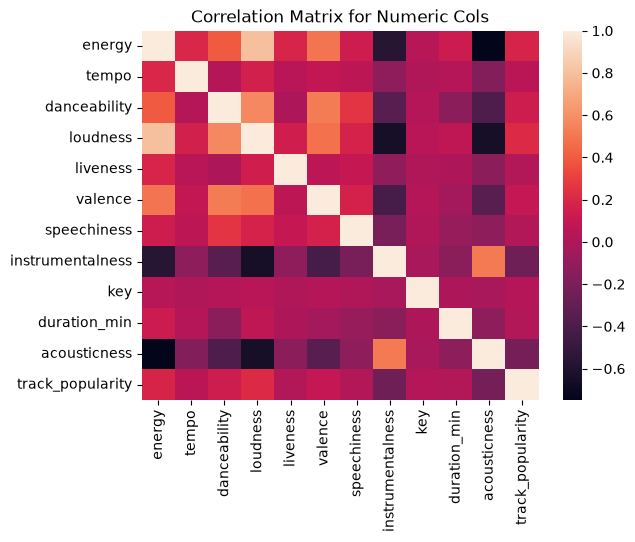

In [53]:
corr_df = spotify_tracks.drop(columns=['track_pop_class_ptsz']).corr(method='pearson',numeric_only=True)

sns.heatmap(data=corr_df)
plt.title("Correlation Matrix for Numeric Cols")
plt.show()



# Now seeing what the correlations above actually look like on plots

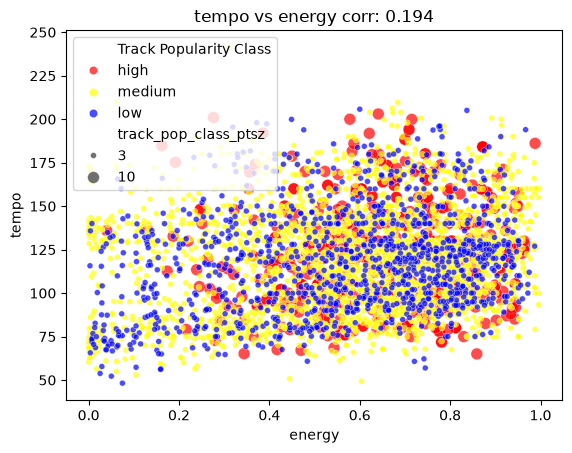

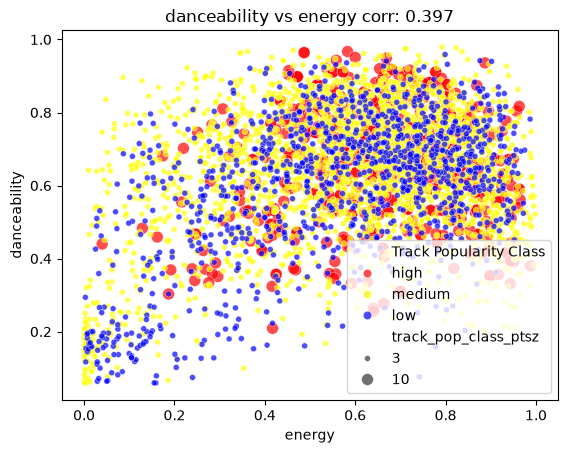

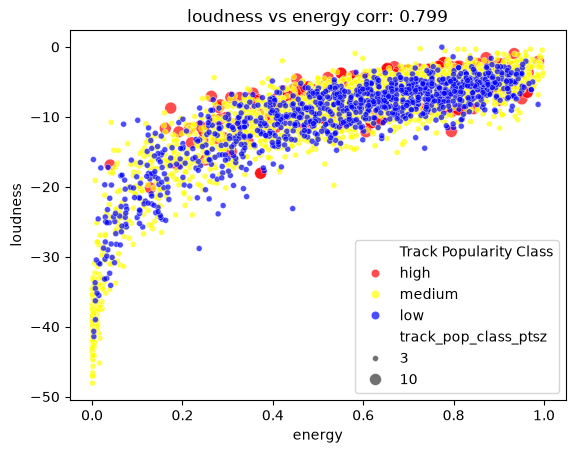

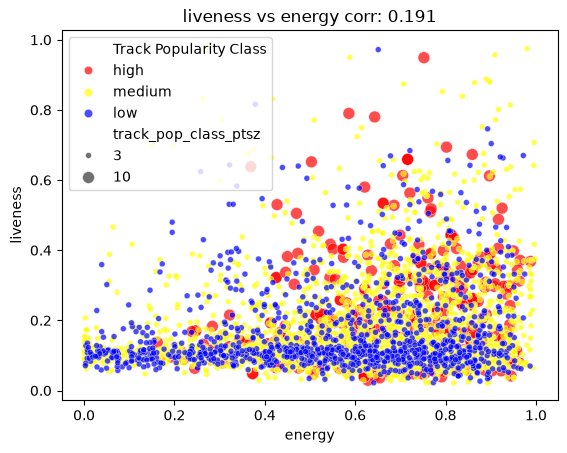

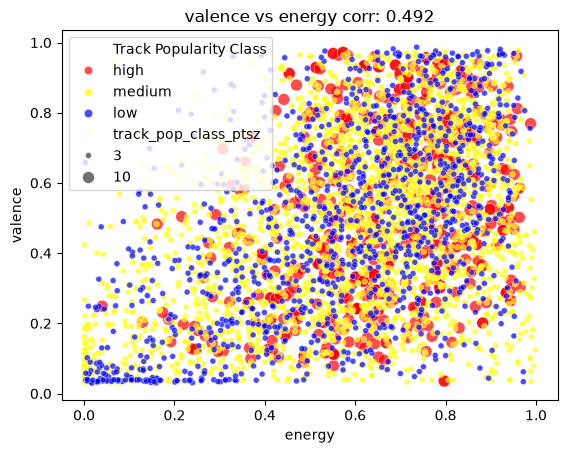

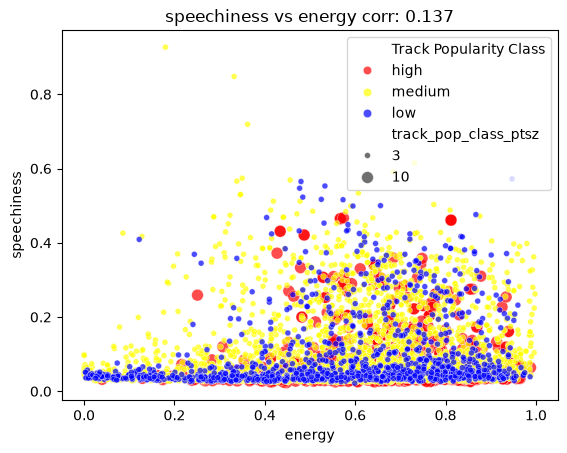

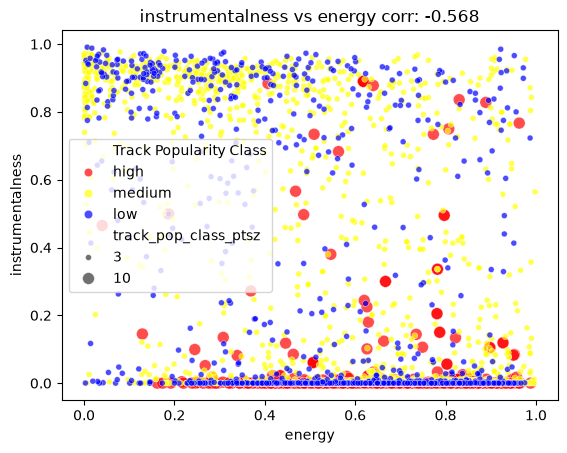

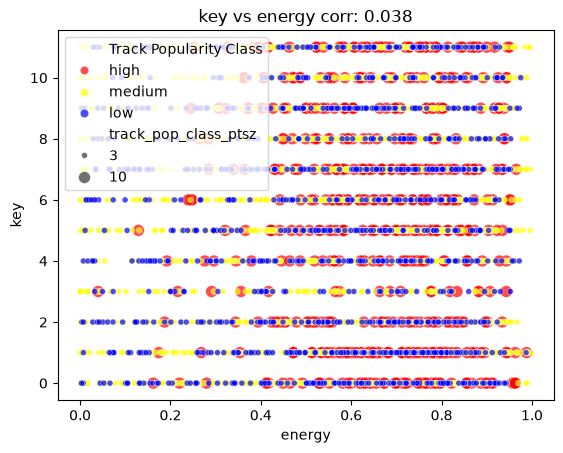

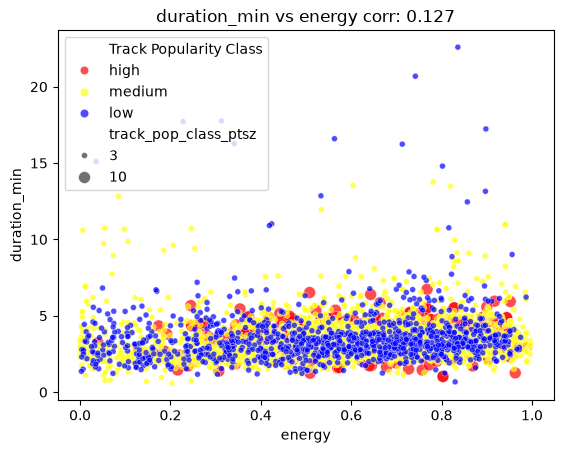

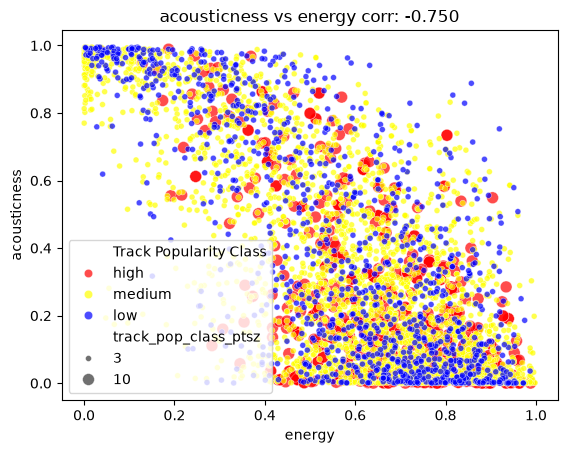

In [55]:
for col in corr_df.columns:
    # This top if is just to exclude point size and color and alpha control columns from the comparisons
    if col != 'energy' and col != 'track_popularity' and col != 'track_pop_class_ptsz' and col != 'Track Popularity Class' and col != 'track_pop_class_alpha':
        sns.scatterplot(data=spotify_tracks,x='energy',hue='Track Popularity Class',y=col,alpha=0.7,palette={"low": "blue","medium":"yellow","high":"red"},size='track_pop_class_ptsz')
        plt.title(f"{col} vs energy corr: {corr_df.loc['energy',col]:.3f}")
        plt.show()

# IMPORTANT, THE LOUDNESS MEASURE IS IN dB. For this visual we are going to look into how loudness and energy might be correlated, and importantly, how many of our entries are approaching the super loud 0 db mark

Max Loudness was: -0.033 and Min Loudness was: -48.069


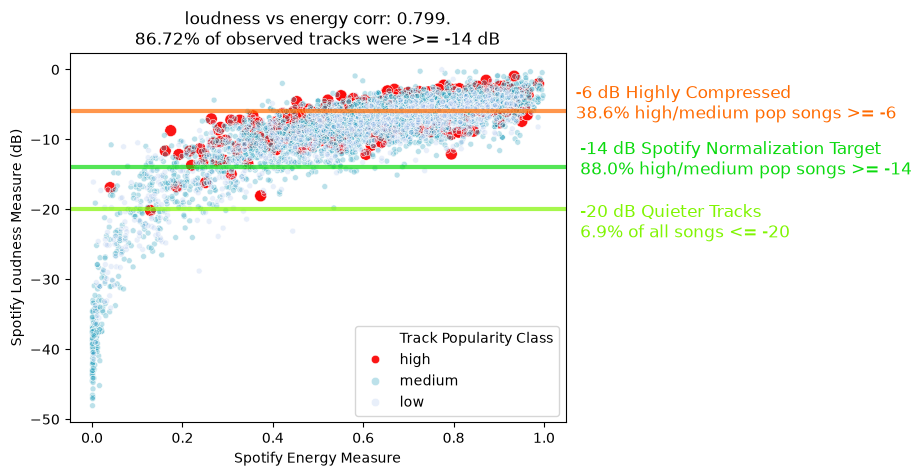

In [47]:
print(f"Max Loudness was: {spotify_tracks['loudness'].max()} and Min Loudness was: {spotify_tracks['loudness'].min()}")
above_msix_pop = (spotify_tracks[(spotify_tracks['loudness'] >= -6) & ((spotify_tracks['Track Popularity Class'] == 'high') | (spotify_tracks['Track Popularity Class'] == 'medium'))].shape[0] / spotify_tracks[((spotify_tracks['Track Popularity Class'] == 'high') | (spotify_tracks['Track Popularity Class'] == 'medium'))].shape[0])*100
above_mfort_pop = (spotify_tracks[(spotify_tracks['loudness'] >= -14) & ((spotify_tracks['Track Popularity Class'] == 'high') | (spotify_tracks['Track Popularity Class'] == 'medium'))].shape[0] / spotify_tracks[((spotify_tracks['Track Popularity Class'] == 'high') | (spotify_tracks['Track Popularity Class'] == 'medium'))].shape[0])*100
bellow_mtwent = (spotify_tracks[(spotify_tracks['loudness'] <= -20)].shape[0] / spotify_tracks.shape[0]) * 100

ax = sns.scatterplot(data=spotify_tracks,x='energy',hue='Track Popularity Class',y='loudness',palette={"low": to_rgba("#8EB1E6",0.2), "medium": to_rgba("#219EBC",0.3), "high": to_rgba("#FB0808",0.95)},size='track_pop_class_ptsz')
plt.axhline(y=-14,xmin=0,xmax=1,color="#0bda0e",lw=3,alpha=0.7)
plt.axhline(y=-20,xmin=0,xmax=1,color="#80f502",lw=3,alpha=0.7)
plt.axhline(y=-6,xmin=0,xmax=1,color="#ff6a00",lw=3,alpha=0.7)

ax.text(x=1.08, y=-15, s=f"-14 dB Spotify Normalization Target\n{above_mfort_pop:.1f}% high/medium pop songs >= -14", fontsize=12, color="#0bda0e")
ax.text(x=1.08, y=-24, s=f"-20 dB Quieter Tracks\n{bellow_mtwent :.1f}% of all songs <= -20", fontsize=12, color="#80f502")
ax.text(x=1.07, y=-7, s=f"-6 dB Highly Compressed\n{above_msix_pop:.1f}% high/medium pop songs >= -6", fontsize=12, color="#ff6a00")


handles, labels = ax.get_legend_handles_labels()
num_pops = len(spotify_tracks['Track Popularity Class'].unique())


above_mfourt = (spotify_tracks[spotify_tracks['loudness'] >= -14].shape[0] / spotify_tracks.shape[0])*100

plt.legend(handles[:num_pops+1],labels[:num_pops+1])

plt.title(f"loudness vs energy corr: {corr_df.loc['energy','loudness']:.3f}.\n{above_mfourt:.2f}% of observed tracks were >= -14 dB")
plt.ylabel("Spotify Loudness Measure (dB)")
plt.xlabel("Spotify Energy Measure")

plt.show()


# Next we'll look into whether longer songs have any meaningful difference in their distributions of duration based on the popularity bin.

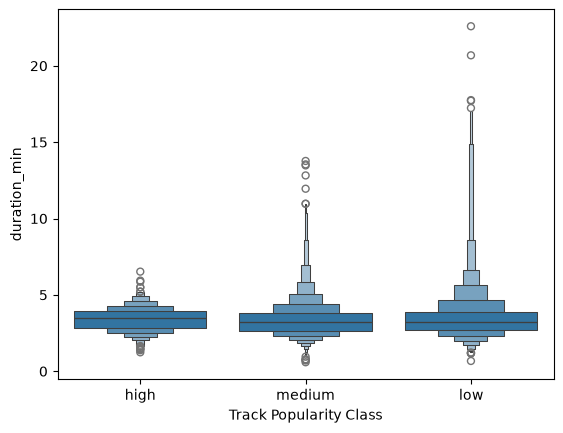

In [40]:
sns.boxenplot(data=spotify_tracks,x='Track Popularity Class',y='duration_min')
plt.show()